# TRỤ CỘT 1: ĐỘ HOÀN THIỆN (MISSING VALUE PROFILING)

✅ Đã tải thành công 331 bản ghi từ: C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\data\glints\glintsraw.json
Đang tiến hành làm phẳng các cấu trúc lồng nhau (Nested Columns)...
Đang làm sạch các giá trị Null ẩn và mảng rỗng...

Bảng thống kê khuyết thiếu (Toàn bộ cột bao gồm cả trường lồng nhau):


,Missing_Count,Missing_Percentage (%)
raw_payload.job_posting_jsonld.baseSalary.value.value,328,99.093656
raw_payload.job_posting_jsonld.applicantLocationRequirements.name,325,98.187311
raw_payload.job_posting_jsonld.applicantLocationRequirements.@type,325,98.187311
raw_payload.job_posting_jsonld.jobLocationType,325,98.187311
raw_payload.job_posting_jsonld.baseSalary.value.maxValue,122,36.858006
raw_payload.job_posting_jsonld.baseSalary.value.minValue,122,36.858006
raw_payload.job_posting_jsonld.baseSalary.currency,119,35.951662
raw_payload.job_posting_jsonld.baseSalary.@type,119,35.951662
raw_payload.job_posting_jsonld.baseSalary.value.unitText,119,35.951662
raw_payload.job_posting_jsonld.baseSalary.value.@type,119,35.951662


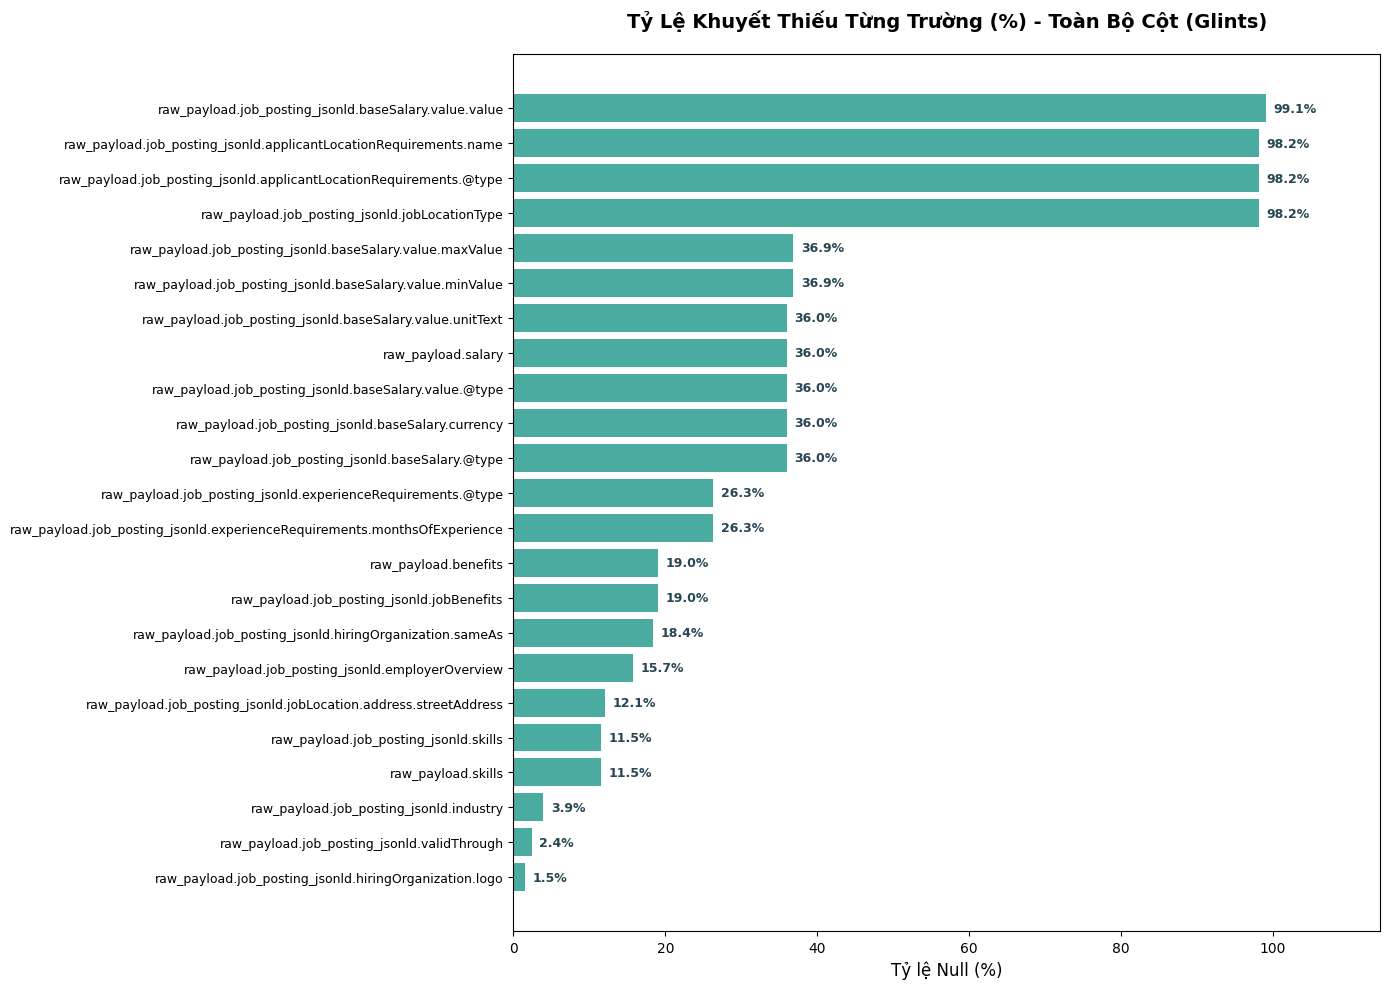

✅ Hoàn tất! Đã lưu và hiển thị biểu đồ tại: C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\01_data_completeness_nested_all.png


In [8]:
import json
import os
import pandas as pd

# Sử dụng đường dẫn tuyệt đối chính xác tới file glintsraw.json trên máy của bạn
file_path = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\data\glints\glintsraw.json"

# Kiểm tra và đọc file an toàn
if os.path.exists(file_path):
  with open(file_path, "r", encoding="utf-8") as f:
    raw_data = json.load(f)

  # Chuyển đổi thành DataFrame
  df_glints_raw = pd.DataFrame(raw_data)
  print(f"✅ Đã tải thành công {len(df_glints_raw)} bản ghi từ: {file_path}")
else:
  print(f"❌ Vẫn không tìm thấy file tại: {file_path}")
  print(
      "Thư mục làm việc hiện tại của Python là:", os.getcwd()
  )  # Kiểm tra vị trí hiện tại

# =================================================================
# SAU KHI LOAD XONG, TIẾP TỤC CHẠY CÁC BƯỚC XỬ LÝ:
# =================================================================
print("Đang tiến hành làm phẳng các cấu trúc lồng nhau (Nested Columns)...")
df_glints_flat = flatten_nested_dataframe(df_glints_raw)

print("Đang làm sạch các giá trị Null ẩn và mảng rỗng...")
df_glints_cleaned = clean_hidden_nulls(df_glints_flat)

# Xem bảng thống kê khuyết thiếu chi tiết
print("\nBảng thống kê khuyết thiếu (Toàn bộ cột bao gồm cả trường lồng nhau):")
display(missing_value_summary(df_glints_cleaned))

# Vẽ và xuất file ảnh báo cáo
save_path = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\01_data_completeness_nested_all.png"
plot_completeness_bar_all(df_glints_cleaned, save_path)

# TRỤ CỘT 2: TÍNH HỢP LỆ VÀ KIỂU DỮ LIỆU

In [9]:
import ast
import re
import numpy as np
import pandas as pd


# =================================================================
# 1. HÀM CHẨN ĐOÁN CHUNG VỀ KIỂU DỮ LIỆU (DTYPES) CHO CỘT PHẲNG
# =================================================================
def check_data_types(df):
  """Kiểm tra kiểu dữ liệu thực tế của toàn bộ các cột sau khi flatten"""
  print("--- 1. TỔNG QUAN KIỂU DỮ LIỆU (GLINTS FLATTENED) ---")
  dtype_summary = pd.DataFrame(df.dtypes, columns=["Thực_tế_Dtype"])
  dtype_summary["Số_lượng_Non_Null"] = df.notnull().sum()
  dtype_summary["Tỷ_lệ_Non_Null (%)"] = (df.notnull().sum() / len(df)) * 100
  dtype_summary["Ví_dụ_Giá_trị"] = df.apply(
      lambda x: x.dropna().iloc[0] if x.notna().any() else np.nan
  )

  # Hiển thị toàn bộ các cột (kể cả cột lồng nhau sau khi chấm phân cấp)
  display(dtype_summary)


# =================================================================
# 2. HÀM CHẨN ĐOÁN CỘT NGÀY THÁNG (TỰ ĐỘNG TÌM THEO TỪ KHÓA)
# =================================================================
def validate_datetime_columns(df):
  """Tự động quét các cột chứa từ khóa thời gian/ngày tháng để kiểm tra định dạng"""
  print("\n--- 2. CHẨN ĐOÁN TÍNH HỢP LỆ NGÀY THÁNG (DYNAMIC SCAN) ---")

  # Tự động nhận diện các cột có tên chứa từ khóa ngày tháng (hỗ trợ cả tiếng Anh lẫn tiếng Việt)
  date_keywords = ["date", "time", "posted", "deadline", "at", "ngay", "thang"]
  potential_date_cols = [
      col
      for col in df.columns
      if any(keyword in col.lower() for keyword in date_keywords)
  ]

  if not potential_date_cols:
    print("Không tìm thấy cột ngày tháng nào dựa trên từ khóa quét tự động.")
    return

  for col in potential_date_cols:
    valid_values = df[col].dropna().astype(str)
    if valid_values.empty:
      continue

    # Các chuẩn phổ biến: ISO 8601 (YYYY-MM-DD...) hoặc DD/MM/YYYY
    iso_pattern = r"^\d{4}-\d{2}-\d{2}"
    vn_pattern = r"^\d{2}/\d{2}/\d{4}$"

    is_iso = valid_values.str.contains(iso_pattern).mean() > 0.5
    is_vn = valid_values.str.match(vn_pattern).mean() > 0.5

    print(f"Cột [{col}]:")
    print(f"  - Mẫu giá trị thực tế: {valid_values.head(2).tolist()}")
    if is_iso:
      print("  - Trạng thái: Chuẩn định dạng ISO 8601.")
    elif is_vn:
      print("  - Trạng thái: Chuẩn định dạng DD/MM/YYYY.")
    else:
      print(
          "  - ⚠️ Cảnh báo: Định dạng ngày tháng dạng chuỗi tự do, cần chuẩn"
          " hóa về ISO 8601 để phân tích."
      )


# =================================================================
# 3. HÀM CHẨN ĐOÁN CỘT SỐ HỌC BỊ STRING HÓA (LƯƠNG, KINH NGHIỆM,...)
# =================================================================
def validate_numeric_strings(df):
  """Phát hiện động các cột định lượng (Lương, Kinh nghiệm, Số lượng) bị lưu dưới dạng chuỗi"""
  print("\n--- 3. CHẨN ĐOÁN SỐ HỌC BỊ STRING HÓA (SALARY, EXPERIENCE) ---")

  num_keywords = [
      "salary",
      "luong",
      "wage",
      "experience",
      "kinh_nghiem",
      "year",
      "nam",
      "price",
  ]
  target_cols = [
      col
      for col in df.columns
      if any(keyword in col.lower() for keyword in num_keywords)
  ]

  if not target_cols:
    print(
        "Không tìm thấy cột số học/lương/kinh nghiệm nào theo từ khóa quét động."
    )
    return

  for col in target_cols:
    samples = df[col].dropna().head(3).tolist()
    dtype_col = df[col].dtype
    print(f"Cột [{col}] (Dtype: {dtype_col}):")
    print(f"  - Ví dụ giá trị thực tế: {samples}")
    if dtype_col == "object":
      print(
          "  - ⚠️ LỖI: Dữ liệu lương/kinh nghiệm đang ở dạng chuỗi văn bản"
          " (Range String/Text)."
      )
      print(
          "    -> Đề xuất Pre-processing: Dùng Regex trích xuất giá trị số"
          " min/max để phục vụ thống kê."
      )
    else:
      print("  - Trạng thái: Đã là kiểu số.")


# =================================================================
# 4. HÀM CHẨN ĐOÁN CẤU TRÚC MẢNG VÀ JSON LỒNG NHAU (TOÀN BỘ CỘT)
# =================================================================
def validate_complex_structures(df):
  """Kiểm tra toàn bộ mọi cột trong DataFrame xem có chứa List, Dict hoặc chuỗi bị string hóa thành List/Dict không"""
  print("\n--- 4. CHẨN ĐOÁN CẤU TRÚC MẢNG VÀ JSON LỒNG NHAU (TOÀN BỘ CỘT) ---")

  found_complex = False
  for col in df.columns:
    non_null_series = df[col].dropna()
    if non_null_series.empty:
      continue

    sample_val = non_null_series.iloc[0]
    actual_type = type(sample_val)

    if actual_type in [list, dict]:
      found_complex = True
      print(f"Cột [{col}]:")
      print(f"  - Cấu trúc: {actual_type.__name__}")
      if actual_type == list:
        inner_type = type(sample_val[0]) if len(sample_val) > 0 else "Empty"
        print(f"    -> List chứa phần tử kiểu: {inner_type}")
      elif actual_type == dict:
        print(f"    -> Dict chứa các khóa mẫu: {list(sample_val.keys())[:5]}")

    elif actual_type == str:
      # Phát hiện các chuỗi có hình thái List hoặc Dict bị string hóa (ví dụ bắt đầu bằng '[{' hoặc '["')
      stripped = sample_val.strip()
      if (stripped.startswith("[") and stripped.endswith("]")) or (
          stripped.startswith("{") and stripped.endswith("}")
      ):
        found_complex = True
        print(f"Cột [{col}]:")
        print(
            "  - ⚠️ LỖI: Cấu trúc dạng List/Dict bị lưu dưới dạng chuỗi văn"
            " bản (Stringified JSON/List)."
        )
        print(
            "    -> Đề xuất: Sử dụng `ast.literal_eval()` hoặc `json.loads()` để"
            " khôi phục lại cấu trúc mảng/dict gốc."
        )

  if not found_complex:
    print(
        "  - Trạng thái: Không phát hiện cấu trúc mảng hoặc dict lồng phức"
        " tạp nào chưa xử lý."
    )


# =================================================================
# THỰC THI PIPELINE CHẨN ĐOÁN TOÀN DIỆN CHO GLINTS
# =================================================================
print(
    "BẮT ĐẦU CHẨN ĐOÁN TÍNH HỢP LỆ DỮ LIỆU TOÀN DIỆN (GLINTS DATASET)\n"
    + "=" * 60
)

# Chạy trên DataFrame đã làm sạch và làm phẳng (df_glints_cleaned)
check_data_types(df_glints_cleaned)
validate_datetime_columns(df_glints_cleaned)
validate_numeric_strings(df_glints_cleaned)
validate_complex_structures(df_glints_cleaned)

BẮT ĐẦU CHẨN ĐOÁN TÍNH HỢP LỆ DỮ LIỆU TOÀN DIỆN (GLINTS DATASET)
--- 1. TỔNG QUAN KIỂU DỮ LIỆU (GLINTS FLATTENED) ---


,Thực_tế_Dtype,Số_lượng_Non_Null,Tỷ_lệ_Non_Null (%),Ví_dụ_Giá_trị
metadata.job_id,object,331,100.000000,00151110-44ff-48bc-9dd9-752c8f632935
metadata.source,object,331,100.000000,glints
metadata.source_url,object,331,100.000000,https://glints.com/vn/opportunities/jobs/retai...
metadata.scraped_at,object,331,100.000000,2026-10-20T11:50:43.440432+00:00
metadata.scraper_version,object,331,100.000000,2.0.0
...,...,...,...,...
raw_payload.job_posting_jsonld.skills,object,293,88.519637,"React.js, jQuery, Laravel, MongoDB, PostgreSQL..."
raw_payload.job_posting_jsonld.jobLocationType,object,6,1.812689,TELECOMMUTE
raw_payload.job_posting_jsonld.applicantLocationRequirements.@type,object,6,1.812689,Country
raw_payload.job_posting_jsonld.applicantLocationRequirements.name,object,6,1.812689,Vietnam



--- 2. CHẨN ĐOÁN TÍNH HỢP LỆ NGÀY THÁNG (DYNAMIC SCAN) ---
Cột [metadata.job_id]:
  - Mẫu giá trị thực tế: ['00151110-44ff-48bc-9dd9-752c8f632935', '00b4d332-8e6e-4714-9853-e816085f7d01']
  - ⚠️ Cảnh báo: Định dạng ngày tháng dạng chuỗi tự do, cần chuẩn hóa về ISO 8601 để phân tích.
Cột [metadata.source]:
  - Mẫu giá trị thực tế: ['glints', 'glints']
  - ⚠️ Cảnh báo: Định dạng ngày tháng dạng chuỗi tự do, cần chuẩn hóa về ISO 8601 để phân tích.
Cột [metadata.source_url]:
  - Mẫu giá trị thực tế: ['https://glints.com/vn/opportunities/jobs/retail-it-executive-infrastructure/00151110-44ff-48bc-9dd9-752c8f632935', 'https://glints.com/vn/opportunities/jobs/dna796-ky-thuat-vien-it-phan-mem-kcn-long-duc-dong-nai/00b4d332-8e6e-4714-9853-e816085f7d01']
  - ⚠️ Cảnh báo: Định dạng ngày tháng dạng chuỗi tự do, cần chuẩn hóa về ISO 8601 để phân tích.
Cột [metadata.scraped_at]:
  - Mẫu giá trị thực tế: ['2026-10-20T11:50:43.440432+00:00', '2026-10-20T11:56:23.177752+00:00']
  - Trạng thái: Chuẩn đị

BIỂU ĐỒ

🔍 Các cột ứng viên chứa thông tin lương phát hiện được: ['metadata.field_hashes.salary', 'raw_payload.salary', 'raw_payload.job_posting_jsonld.baseSalary.@type', 'raw_payload.job_posting_jsonld.baseSalary.currency', 'raw_payload.job_posting_jsonld.baseSalary.value.@type', 'raw_payload.job_posting_jsonld.baseSalary.value.minValue', 'raw_payload.job_posting_jsonld.baseSalary.value.maxValue', 'raw_payload.job_posting_jsonld.baseSalary.value.unitText', 'raw_payload.job_posting_jsonld.baseSalary.value.value']
👉 Đang sử dụng cột [metadata.field_hashes.salary] để phân tích phân phối lương...


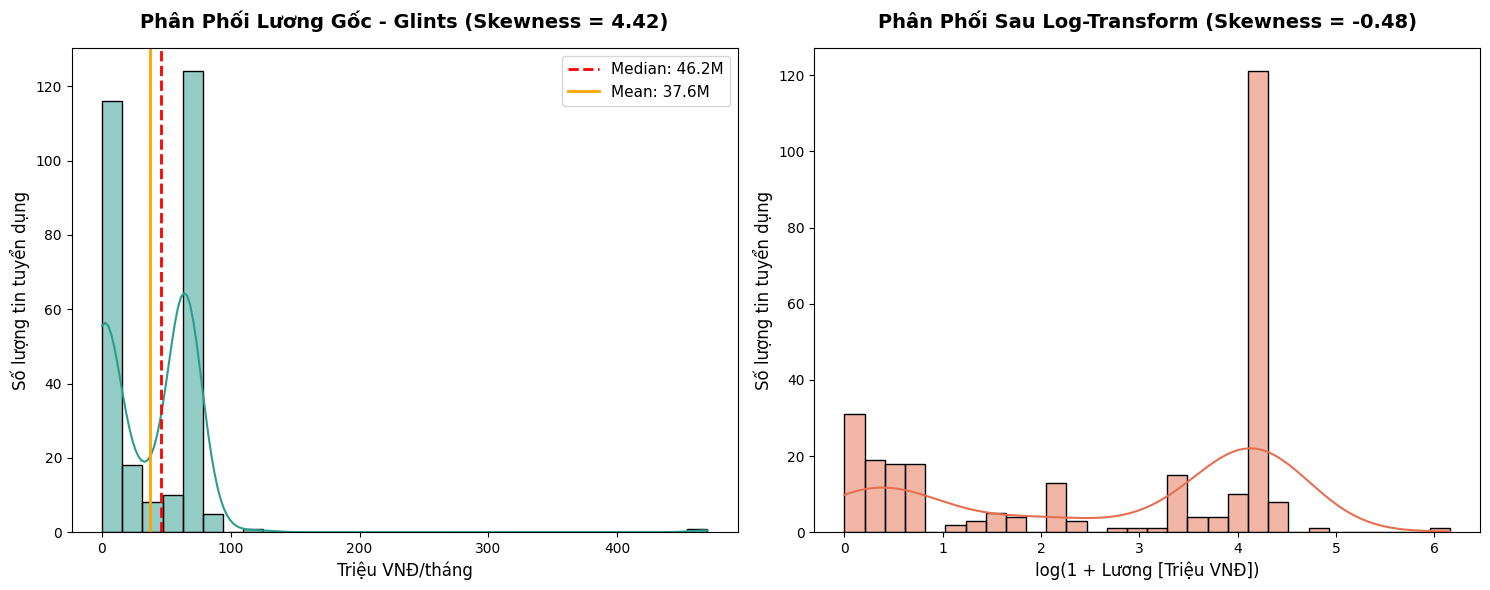

✅ Hoàn tất! Đã lưu và hiển thị biểu đồ phân phối lương tại: C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\02_salary_distribution_skewness.png


In [12]:
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# =================================================================
# 1. HÀM TIỀN XỬ LÝ (TRÍCH XUẤT LƯƠNG TỪ CHUỖI / DỮ LIỆU ĐA DẠNG)
# =================================================================
def extract_max_salary(salary_val):
    """Bóc tách mức lương tối đa từ chuỗi văn bản hoặc số (đơn vị: Triệu VNĐ).

    Hỗ trợ xử lý dữ liệu thô đa dạng từ Glints (chuỗi, số, v.v.).
    """
    if pd.isna(salary_val):
        return np.nan

    # Nếu giá trị bản chất đã là số (int/float)
    if isinstance(salary_val, (int, float)):
        val_num = float(salary_val)
        if val_num <= 0 or val_num > 500:
            return np.nan
        if val_num >= 1000:
            val_num = val_num / 1_000_000
        return val_num

    val = str(salary_val).lower().strip()

    # Bỏ qua các tin không có số liệu cụ thể hoặc thỏa thuận
    if any(
        kw in val
        for kw in [
            "thỏa thuận",
            "thoả thuận",
            "thương lượng",
            "cạnh tranh",
            "không công khai",
        ]
    ):
        return np.nan

    # Thay dấu phẩy thành chấm để xử lý số thập phân
    val = val.replace(",", ".")

    # Tìm tất cả các con số trong chuỗi
    nums = re.findall(r"\d+\.?\d*", val)

    if not nums:
        return np.nan

    nums = [float(n) for n in nums]
    max_val = max(nums)

    # Quy đổi về mốc Triệu VNĐ nếu giá trị lớn (tính bằng VNĐ)
    if max_val >= 1000:
        max_val = max_val / 1_000_000

    # Loại bỏ các ngoại lai do gõ nhầm
    if max_val <= 0 or max_val > 500:
        return np.nan

    return max_val


# =================================================================
# 2. HÀM TỰ ĐỘNG NHẬN DIỆN CỘT LƯƠNG VÀ VẼ BIỂU ĐỒ PHÂN PHỐI
# =================================================================
def plot_salary_distribution_glints(df, save_path):
    """Tự động quét các cột liên quan đến lương sau khi flatten,

    trích xuất dữ liệu, vẽ biểu đồ phân phối gốc và Log-Transform cho Glints.
    """
    # Quét động các cột chứa từ khóa lương trên toàn bộ cột phẳng
    salary_keywords = ["salary", "luong", "wage", "baseSalary"]
    candidate_cols = [
        col
        for col in df.columns
        if any(kw in col.lower() for kw in salary_keywords)
    ]

    if not candidate_cols:
        print(
            "❌ Không tìm thấy cột nào chứa từ khóa lương trong DataFrame đã flatten."
        )
        return

    print(f"🔍 Các cột ứng viên chứa thông tin lương phát hiện được: {candidate_cols}")

    # Ưu tiên lựa chọn cột có khả năng chứa dữ liệu lương chính xác nhất
    target_col = candidate_cols[0]
    for col in candidate_cols:
        if "raw_payload" in col or "salary" in col:
            target_col = col
            break

    print(f"👉 Đang sử dụng cột [{target_col}] để phân tích phân phối lương...")

    # 1. Trích xuất dữ liệu lương thực tế
    salaries_millions = df[target_col].apply(extract_max_salary).dropna()

    if salaries_millions.empty:
        print(f"❌ Cột [{target_col}] không có dữ liệu lương hợp lệ sau khi trích xuất.")
        return

    # 2. Khởi tạo không gian vẽ (2 biểu đồ song song)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # ==========================================
    # BIỂU ĐỒ TRÁI: PHÂN PHỐI LƯƠNG GỐC
    # ==========================================
    sns.histplot(
        salaries_millions, kde=True, ax=axes[0], color="#2a9d8f", bins=30
    )

    median_val = salaries_millions.median()
    mean_val = salaries_millions.mean()
    skewness_val = salaries_millions.skew()

    axes[0].axvline(
        median_val,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Median: {median_val:.1f}M",
    )
    axes[0].axvline(
        mean_val,
        color="orange",
        linestyle="-",
        linewidth=2,
        label=f"Mean: {mean_val:.1f}M",
    )

    axes[0].set_title(
        f"Phân Phối Lương Gốc - Glints (Skewness = {skewness_val:.2f})",
        fontsize=14,
        pad=15,
        fontweight="bold",
    )
    axes[0].set_xlabel("Triệu VNĐ/tháng", fontsize=12)
    axes[0].set_ylabel("Số lượng tin tuyển dụng", fontsize=12)
    axes[0].legend(fontsize=11)

    # ==========================================
    # BIỂU ĐỒ PHẢI: LOG-TRANSFORMED
    # ==========================================
    log_salaries = np.log1p(salaries_millions)
    log_skewness = log_salaries.skew()

    sns.histplot(log_salaries, kde=True, ax=axes[1], color="#e76f51", bins=30)

    axes[1].set_title(
        f"Phân Phối Sau Log-Transform (Skewness = {log_skewness:.2f})",
        fontsize=14,
        pad=15,
        fontweight="bold",
    )
    axes[1].set_xlabel("log(1 + Lương [Triệu VNĐ])", fontsize=12)
    axes[1].set_ylabel("Số lượng tin tuyển dụng", fontsize=12)

    # 3. Căn chỉnh, Lưu file và Hiển thị trong Notebook
    plt.tight_layout()
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")

    # Hiển thị trực tiếp hình ảnh ngay trong Jupyter Notebook
    plt.show()
    plt.close()

    print(f"✅ Hoàn tất! Đã lưu và hiển thị biểu đồ phân phối lương tại: {save_path}")


# =================================================================
# THỰC THI PIPELINE PHÂN TÍCH LƯƠNG CHO DỮ LIỆU GLINTS
# =================================================================
# Cập nhật đường dẫn tuyệt đối chính xác theo yêu cầu
save_path_chart_2 = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\02_salary_distribution_skewness.png"

# Chạy hàm trên DataFrame đã làm phẳng và làm sạch (df_glints_cleaned)
plot_salary_distribution_glints(df_glints_cleaned, save_path_chart_2)

# TRỤ CỘT 3: TÍNH DUY NHẤT VÀ TRÙNG LẶP

In [13]:
import numpy as np
import pandas as pd


def check_duplication_glints(df):
    """Hàm đo lường tỷ lệ trùng lặp dữ liệu theo 3 cấp độ (Động) cho Glints:

    1. Trùng lặp tuyệt đối (Exact duplicates)
    2. Trùng lặp khóa định danh (ID / URL duplicates - Quét động)
    3. Trùng lặp logic (Semantic duplicates - Quét động các cột Tiêu đề, Công
    ty, Địa điểm)
    """
    print("--- TRỤ CỘT 3: CHẨN ĐOÁN TÍNH DUY NHẤT & TRÙNG LẶP (GLINTS) ---")
    total_records = len(df)
    print(f"Tổng số bản ghi ban đầu: {total_records}")

    if total_records == 0:
        print("❌ DataFrame rỗng, không thể kiểm tra trùng lặp.")
        return

    # ==========================================
    # 1. TRÙNG LẶP TUYỆT ĐỐI (100% CÁC CỘT GIỐNG NHAU)
    # ==========================================
    # Ép toàn bộ DataFrame về dạng chuỗi để tránh lỗi unhashable type do chứa list/dict
    df_string_format = df.astype(str)
    exact_dups = df_string_format.duplicated().sum()
    exact_pct = (exact_dups / total_records) * 100

    print(f"\n1. Trùng lặp tuyệt đối (Exact Duplicates):")
    print(f"   - Số lượng: {exact_dups} bản ghi")
    print(f"   - Tỷ lệ: {exact_pct:.2f}%")

    # ==========================================
    # 2. TRÙNG LẶP KHÓA ĐỊNH DANH (ID / URL - DYNAMIC SCAN)
    # ==========================================
    id_keywords = ["job_id", "jobid", "id", "url", "link"]
    id_cols = [
        col
        for col in df.columns
        if any(kw in col.lower() for kw in id_keywords)
        and (
            "metadata" in col.lower()
            or "source" in col.lower()
            or col == "id"
            or "job" in col.lower()
        )
    ]

    # Fallback rộng hơn nếu danh sách lọc trên trống
    if not id_cols:
        id_cols = [
            col
            for col in df.columns
            if any(kw in col.lower() for kw in ["id", "url"])
        ]

    id_col = id_cols[0] if id_cols else None

    if id_col:
        id_dups = df.duplicated(subset=[id_col]).sum()
        id_pct = (id_dups / total_records) * 100
        print(
            f"\n2. Trùng lặp khóa định danh (Cột nhận diện tự động: '{id_col}'):"
        )
        print(f"   - Số lượng: {id_dups} bản ghi")
        print(f"   - Tỷ lệ: {id_pct:.2f}%")
    else:
        id_dups = 0
        print(
            "\n2. Trùng lặp khóa định danh: Không tìm thấy cột chứa Job ID hay"
            " URL phù hợp."
        )

    # ==========================================
    # 3. TRÙNG LẶP LOGIC (DYNAMIC SCAN: TITLE + COMPANY + LOCATION)
    # ==========================================
    # Tự động quét các cột đặc trưng dựa trên từ khóa tiếng Anh/Việt sau khi flatten
    title_cols = [
        c
        for c in df.columns
        if any(kw in c.lower() for kw in ["title", "tieu_de", "position"])
    ]
    company_cols = [
        c
        for c in df.columns
        if any(kw in c.lower() for kw in ["company", "cong_ty", "employer"])
    ]
    location_cols = [
        c
        for c in df.columns
        if any(kw in c.lower() for kw in ["location", "address", "dia_diem"])
    ]

    t_col = title_cols[0] if title_cols else None
    c_col = company_cols[0] if company_cols else None
    l_col = location_cols[0] if location_cols else None

    existing_logical_cols = [col for col in [t_col, c_col, l_col] if col]

    if len(existing_logical_cols) >= 2:
        # Chuẩn hóa (lower-case & strip) để phát hiện tin đăng lại nhưng khác kiểu gõ chữ
        temp_df = (
            df[existing_logical_cols]
            .fillna("")
            .astype(str)
            .apply(lambda x: x.str.lower().str.strip())
        )
        logical_dups = temp_df.duplicated().sum()
        logical_pct = (logical_dups / total_records) * 100

        print(f"\n3. Trùng lặp logic (Theo các cột {existing_logical_cols}):")
        print(f"   - Số lượng: {logical_dups} bản ghi")
        print(f"   - Tỷ lệ: {logical_pct:.2f}%")
    else:
        logical_dups = 0
        print(
            "\n3. Trùng lặp logic: Không tìm đủ các cột đặc trưng (Tiêu đề,"
            " Công ty, Địa điểm) để kiểm tra."
        )

    # ==========================================
    # KẾT LUẬN & ĐỀ XUẤT PRE-PROCESSING
    # ==========================================
    print("\n" + "=" * 50)
    max_dups = max(exact_dups, id_dups if id_col else 0, logical_dups)
    if max_dups > 0:
        print(
            "⚠️ CHẨN ĐOÁN: Dữ liệu Glints chứa các bản ghi trùng lặp"
            " (Overlapping)."
        )
        print("💡 HƯỚNG XỬ LÝ (Pre-processing):")
        if id_col:
            print(
                f"   -> Bước 1: Gọi drop_duplicates(subset=['{id_col}']) để"
                " loại bỏ tin trùng lặp do vòng lặp phân trang (crawler loop)."
            )
        if existing_logical_cols:
            print(
                f"   -> Bước 2: Gọi drop_duplicates(subset={existing_logical_cols})"
                " để lọc bỏ các tin tuyển dụng đăng lặp (Repost) từ nhà tuyển"
                " dụng."
            )
    else:
        print(
            "✅ TUYỆT VỜI: Không phát hiện bản ghi trùng lặp nào trong dữ liệu"
            " Glints."
        )


# =================================================================
# THỰC THI PIPELINE CHẨN ĐOÁN TRÙNG LẶP CHO GLINTS
# =================================================================
check_duplication_glints(df_glints_cleaned)

--- TRỤ CỘT 3: CHẨN ĐOÁN TÍNH DUY NHẤT & TRÙNG LẶP (GLINTS) ---
Tổng số bản ghi ban đầu: 331

1. Trùng lặp tuyệt đối (Exact Duplicates):
   - Số lượng: 0 bản ghi
   - Tỷ lệ: 0.00%

2. Trùng lặp khóa định danh (Cột nhận diện tự động: 'metadata.job_id'):
   - Số lượng: 0 bản ghi
   - Tỷ lệ: 0.00%

3. Trùng lặp logic (Theo các cột ['metadata.field_hashes.job-title', 'metadata.field_hashes.company-name', 'raw_payload.job_posting_jsonld.jobLocation.@type']):
   - Số lượng: 9 bản ghi
   - Tỷ lệ: 2.72%

⚠️ CHẨN ĐOÁN: Dữ liệu Glints chứa các bản ghi trùng lặp (Overlapping).
💡 HƯỚNG XỬ LÝ (Pre-processing):
   -> Bước 1: Gọi drop_duplicates(subset=['metadata.job_id']) để loại bỏ tin trùng lặp do vòng lặp phân trang (crawler loop).
   -> Bước 2: Gọi drop_duplicates(subset=['metadata.field_hashes.job-title', 'metadata.field_hashes.company-name', 'raw_payload.job_posting_jsonld.jobLocation.@type']) để lọc bỏ các tin tuyển dụng đăng lặp (Repost) từ nhà tuyển dụng.


# TRỤ CỘT 5: BIAS AND BALANCE PROFILING

--- CHẨN ĐOÁN THIÊN LỆCH & MẤT CÂN BẰNG TOÀN DIỆN (GLINTS) ---

1. Phân bổ Mức lương (Cột: metadata.field_hashes.salary):
   - 9974b64533073d80e25ae69a7aaf9c3f3c84ebaab1bb9459c1438c6b54eb1294: 119 tin (36.0%)
   - c4d6874db405966d559d7513afc808f3f2fb5bcfbaaaa0f997cf37fdc3fe7a42: 13 tin (3.9%)
   - 25aa3dbe754528d2684e51ac7a18a4df8dacd2ae30c80383b1e431708bee3f5e: 12 tin (3.6%)
   - 54bf33daa6926a7958ec8f3e2aac9cc0b17e2d628a887277f511f8a70e42c097: 10 tin (3.0%)
   - b2f2e5dddc6f5117268a3f3de1b1966acfe28864642cbec46287b551371c4a4b: 8 tin (2.4%)
   => Tỷ lệ trống/không công khai: 0.0%

3. Phân bổ Thiên lệch Địa điểm (Cột: raw_payload.job_posting_jsonld.jobLocation.@type):
   - Place: 331 tin (100.0%)

4. Phân bổ Yêu cầu Học vấn (Cột: raw_payload.job_posting_jsonld.educationRequirements.@type):
   - EducationalOccupationalCredential: 331 tin (100.0%)

5. Phân bổ Yêu cầu Kinh nghiệm (Cột: raw_payload.job_posting_jsonld.experienceRequirements.@type):
   - OccupationalExperienceRequirements: 2

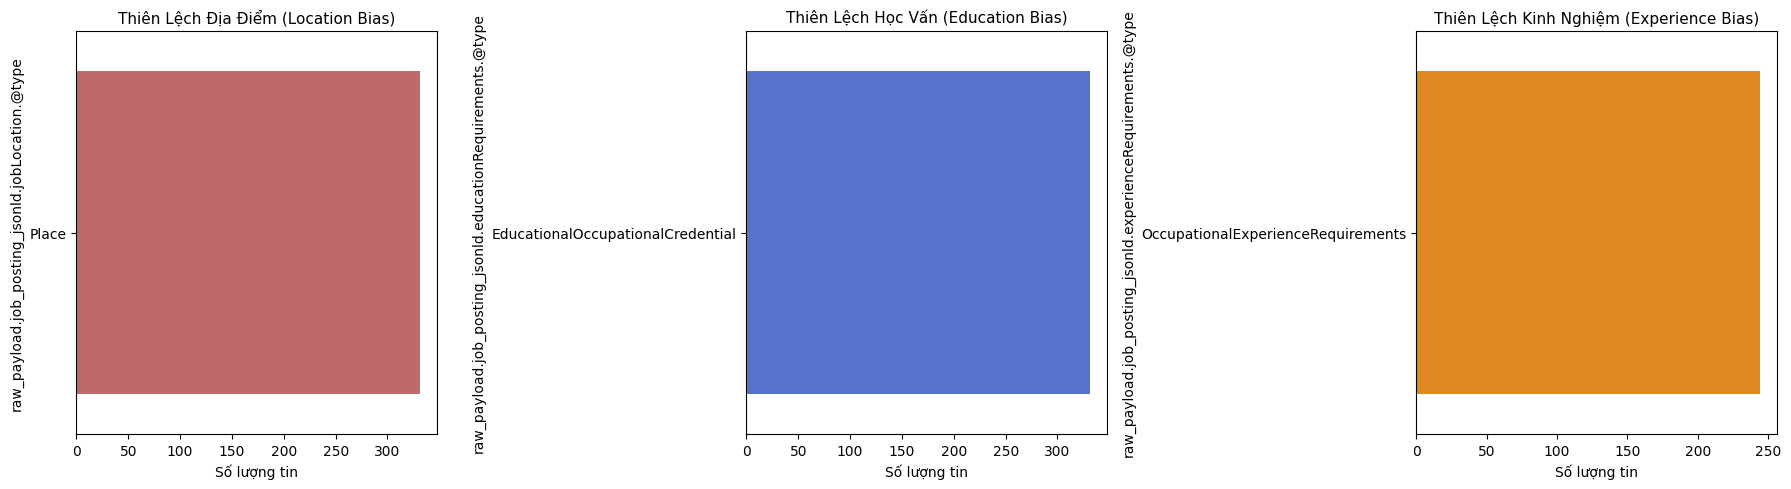

✅ Đã lưu Biểu đồ Thiên lệch Nâng cao tại: C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\05_location_edu_exp_bias.png


In [20]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# =================================================================
# 1. HÀM ĐÁNH GIÁ CHỈ SỐ MẤT CÂN BẰNG: SALARY, SKILLS, LOCATION & REQS (TEXT REPORT)
# =================================================================
def profile_comprehensive_bias_glints(df):
    print("--- CHẨN ĐOÁN THIÊN LỆCH & MẤT CÂN BẰNG TOÀN DIỆN (GLINTS) ---")
    total_records = len(df)
    if total_records == 0:
        print("❌ DataFrame rỗng.")
        return

    # --- 1. Quét động cột Mức lương (Salary) ---
    salary_keywords = ["salary", "luong", "thu_nhap", "compensation"]
    salary_cols = [col for col in df.columns if any(kw in col.lower() for kw in salary_keywords)]
    salary_col = salary_cols[0] if salary_cols else None

    if salary_col:
        print(f"\n1. Phân bổ Mức lương (Cột: {salary_col}):")
        salary_counts = df[salary_col].value_counts().head(5)
        for sal, count in salary_counts.items():
            pct = (count / total_records) * 100
            print(f"   - {sal}: {count} tin ({pct:.1f}%)")
        missing_salary = df[salary_col].isna().sum()
        unpublic_salary = df[salary_col].astype(str).str.contains("không công khai|Negotiable|Thỏa thuận", case=False, na=False).sum()
        print(f"   => Tỷ lệ trống/không công khai: {(missing_salary + unpublic_salary)/total_records*100:.1f}%")

    # --- 2. Quét động cột Kỹ năng (Skills) ---
    skill_keywords = ["skill", "keyword", "tag", "technology", "ky_nang"]
    skill_cols = [col for col in df.columns if any(kw in col.lower() for kw in skill_keywords)]
    skill_col = skill_cols[0] if skill_cols else None

    if skill_col:
        all_skills = df[skill_col].dropna().explode().astype(str).str.strip()
        valid_skills = all_skills[all_skills.str.len() <= 30]
        if not valid_skills.empty:
            skill_counts = valid_skills.value_counts()
            unique_skills = len(skill_counts)
            cumulative_pct = (skill_counts.cumsum() / len(valid_skills)) * 100
            top_80 = cumulative_pct[cumulative_pct <= 80].count()
            print(f"\n2. Chẩn đoán Kỹ năng (Pareto 80/20): Top {top_80} / {unique_skills} kỹ năng ({top_80/unique_skills*100:.1f}%) thống trị 80% thị phần.")

    # --- 3. Quét động cột Địa điểm (Job Location) ---
    loc_keywords = ["location", "dia_diem", "address", "khu_vuc", "region"]
    loc_cols = [col for col in df.columns if any(kw in col.lower() for kw in loc_keywords)]
    loc_col = loc_cols[0] if loc_cols else None

    if loc_col:
        print(f"\n3. Phân bổ Thiên lệch Địa điểm (Cột: {loc_col}):")
        loc_counts = df[loc_col].value_counts().head(5)
        for loc, count in loc_counts.items():
            print(f"   - {loc}: {count} tin ({(count/total_records)*100:.1f}%)")
    else:
        print("\n3. Địa điểm: Không tìm thấy cột vị trí phù hợp.")

    # --- 4. Quét động cột Yêu cầu Học vấn (Education Requirements) ---
    edu_keywords = ["education", "hoc_van", "bang_cap", "credential"]
    edu_cols = [col for col in df.columns if any(kw in col.lower() for kw in edu_keywords)]
    edu_col = edu_cols[0] if edu_cols else None

    if edu_col:
        print(f"\n4. Phân bổ Yêu cầu Học vấn (Cột: {edu_col}):")
        edu_counts = df[edu_col].value_counts().head(5)
        for edu, count in edu_counts.items():
            print(f"   - {edu}: {count} tin ({(count/total_records)*100:.1f}%)")
    else:
        print("\n4. Học vấn: Không tìm thấy cột học vấn phù hợp.")

    # --- 5. Quét động cột Yêu cầu Kinh nghiệm (Experience Requirements) ---
    exp_keywords = ["experience", "kinh_nghiem", "nam_kinh_nghiem"]
    exp_cols = [col for col in df.columns if any(kw in col.lower() for kw in exp_keywords)]
    exp_col = exp_cols[0] if exp_cols else None

    if exp_col:
        print(f"\n5. Phân bổ Yêu cầu Kinh nghiệm (Cột: {exp_col}):")
        exp_counts = df[exp_col].value_counts().head(5)
        for exp, count in exp_counts.items():
            print(f"   - {exp}: {count} tin ({(count/total_records)*100:.1f}%)")
    else:
        print("\n5. Kinh nghiệm: Không tìm thấy cột kinh nghiệm phù hợp.")


# =================================================================
# 2. HÀM VẼ BIỂU ĐỒ: PARETO 80/20 KỸ NĂNG
# =================================================================
def plot_skills_pareto_glints(df, save_path):
    skill_keywords = ["skill", "keyword", "tag", "technology", "ky_nang"]
    skill_cols = [col for col in df.columns if any(kw in col.lower() for kw in skill_keywords)]
    if not skill_cols:
        return
    skill_col = skill_cols[0]
    all_skills = df[skill_col].dropna().explode().astype(str).str.strip()
    valid_skills = all_skills[all_skills.str.len() <= 30]
    top20 = valid_skills.value_counts().head(20).reset_index()
    if top20.empty:
        return
    top20.columns = ["Skill", "Frequency"]
    top20["Cum_Percent"] = (top20["Frequency"].cumsum() / top20["Frequency"].sum()) * 100

    fig, ax1 = plt.subplots(figsize=(13, 6))
    ax2 = ax1.twinx()
    sns.barplot(data=top20, x="Skill", y="Frequency", ax=ax1, color="mediumseagreen")
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right", fontsize=10)
    ax1.set_ylabel("Tần suất xuất hiện", fontsize=11)
    ax1.set_xlabel("Kỹ năng / Công nghệ", fontsize=11)

    sns.lineplot(data=top20, x="Skill", y="Cum_Percent", ax=ax2, color="#d62828", marker="o", linewidth=2.5)
    ax2.axhline(80, color="gray", linestyle="--", alpha=0.7, label="Ngưỡng 80% Pareto")
    ax2.set_ylabel("Tỷ lệ tích lũy (%)", fontsize=11)
    ax2.set_ylim(0, 105)
    ax2.legend(loc="lower right")

    plt.title("Phân Phối Tần Suất Kỹ Năng & Pareto (Glints)", fontsize=14, fontweight="bold", pad=15)
    plt.tight_layout()
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"✅ Đã lưu Biểu đồ Pareto Skills tại: {save_path}")


# =================================================================
# 3. HÀM VẼ BIỂU ĐỒ: ĐÁNH GIÁ THIÊN LỆCH (LOCATION, EDUCATION, EXPERIENCE)
# =================================================================
def plot_advanced_biases_glints(df, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Thiên lệch Địa điểm (jobLocation Bias)
    loc_keywords = ["location", "dia_diem", "address", "khu_vuc", "region"]
    loc_cols = [col for col in df.columns if any(kw in col.lower() for kw in loc_keywords)]
    if loc_cols and not df[loc_cols[0]].dropna().empty:
        loc_counts = df[loc_cols[0]].dropna().astype(str).str.strip().value_counts().head(6)
        sns.barplot(x=loc_counts.values, y=loc_counts.index, ax=axes[0], color="indianred")
        axes[0].set_title("Thiên Lệch Địa Điểm (Location Bias)", fontsize=11)
        axes[0].set_xlabel("Số lượng tin", fontsize=10)
    else:
        axes[0].text(0.5, 0.5, "Không có dữ liệu Địa điểm", ha="center", va="center")

    # 2. Thiên lệch Học vấn (educationRequirements Bias)
    edu_keywords = ["education", "hoc_van", "bang_cap", "credential"]
    edu_cols = [col for col in df.columns if any(kw in col.lower() for kw in edu_keywords)]
    if edu_cols and not df[edu_cols[0]].dropna().empty:
        edu_counts = df[edu_cols[0]].dropna().astype(str).str.strip().value_counts().head(6)
        sns.barplot(x=edu_counts.values, y=edu_counts.index, ax=axes[1], color="royalblue")
        axes[1].set_title("Thiên Lệch Học Vấn (Education Bias)", fontsize=11)
        axes[1].set_xlabel("Số lượng tin", fontsize=10)
    else:
        axes[1].text(0.5, 0.5, "Không có dữ liệu Học vấn", ha="center", va="center")

    # 3. Thiên lệch Kinh nghiệm (experienceRequirements Bias)
    exp_keywords = ["experience", "kinh_nghiem", "nam_kinh_nghiem"]
    exp_cols = [col for col in df.columns if any(kw in col.lower() for kw in exp_keywords)]
    if exp_cols and not df[exp_cols[0]].dropna().empty:
        exp_counts = df[exp_cols[0]].dropna().astype(str).str.strip().value_counts().head(6)
        sns.barplot(x=exp_counts.values, y=exp_counts.index, ax=axes[2], color="darkorange")
        axes[2].set_title("Thiên Lệch Kinh Nghiệm (Experience Bias)", fontsize=11)
        axes[2].set_xlabel("Số lượng tin", fontsize=10)
    else:
        axes[2].text(0.5, 0.5, "Không có dữ liệu Kinh nghiệm", ha="center", va="center")

    plt.tight_layout()
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"✅ Đã lưu Biểu đồ Thiên lệch Nâng cao tại: {save_path}")


# =================================================================
# THỰC THI PIPELINE PHÂN TÍCH THIÊN LỆCH MỚI
# =================================================================
# 1. Chạy báo cáo dạng Text
profile_comprehensive_bias_glints(df_glints_cleaned)

# 2. Định nghĩa đường dẫn lưu biểu đồ
path_chart_pareto = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\03_skills_pareto_distribution.png"
path_chart_biases = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\05_location_edu_exp_bias.png"

# 3. Xuất biểu đồ hình ảnh
plot_skills_pareto_glints(df_glints_cleaned, path_chart_pareto)
plot_advanced_biases_glints(df_glints_cleaned, path_chart_biases)

--- CHẨN ĐOÁN THIÊN LỆCH: SALARY & ADDRESSREGION ---

1. Phân bổ Mức lương (Cột: raw_payload.salary):
   - ₫15.000.000-20.000.000/Tháng: 13 tin (3.9%)
   - ₫10.000.000-15.000.000/Tháng: 12 tin (3.6%)
   - ₫20.000.000-30.000.000/Tháng: 10 tin (3.0%)
   - ₫8.500.000-9.000.000/Tháng: 8 tin (2.4%)
   - ₫10.000.000-13.000.000/Tháng: 6 tin (1.8%)
   => Số lượng trống (NaN): 119 (36.0%)
   => Số lượng không công khai/thỏa thuận: 0 (0.0%)

2. Phân bổ Khu vực Địa lý (Cột: raw_payload.job_posting_jsonld.jobLocation.address.addressRegion):
   - Thành phố Hồ Chí Minh: 154 tin (46.5%)
   - Hà Nội: 92 tin (27.8%)
   - Đồng Nai: 34 tin (10.3%)
   - Bình Dương: 27 tin (8.2%)
   - Long An: 11 tin (3.3%)
   => Số lượng trống (NaN): 0 (0.0%)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17464\1668750508.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right", fontsize=10)


✅ Đã lưu Biểu đồ Pareto Skills (Glints) tại: C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\03_skills_pareto_distribution.png


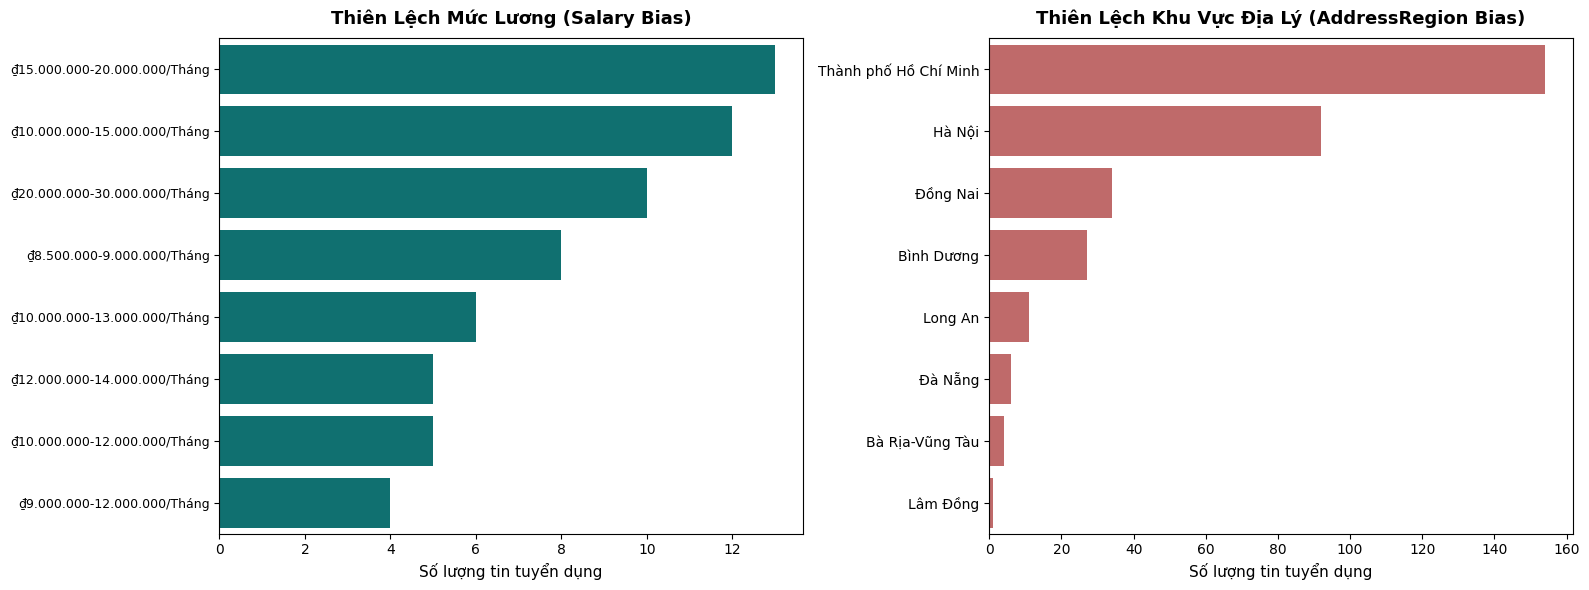

✅ Đã lưu Biểu đồ Thiên lệch Salary & AddressRegion tại: C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\04_salary_and_addressregion_bias.png


In [37]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def flatten_glints_json(df):
    df_processed = df.copy()
    def extract_skills(row):
        # Thử lấy từ raw_payload -> job_posting_jsonld -> skills
        raw = row.get('raw_payload')
        if isinstance(raw, dict):
            jsonld = raw.get('job_posting_jsonld', {})
            if isinstance(jsonld, dict):
                s = jsonld.get('skills')
                if isinstance(s, str):
                    return [skill.strip() for skill in s.split(',')]
        # Thử từ cột skills truyền thống nếu có sẵn
        if 'skills' in row and isinstance(row['skills'], str):
            return [skill.strip() for skill in row['skills'].split(',')]
        elif 'skills' in row and isinstance(row['skills'], list):
            return row['skills']
        return []

    df_processed['parsed_skills'] = df_processed.apply(extract_skills, axis=1)
    
    return df_processed

# =================================================================
# HÀM HỖ TRỢ: LÀM PHẲNG CẤU TRÚC JSON LỒNG NHAU (FLATTEN)
# =================================================================
def flatten_json_columns(df):
    df_processed = df.copy()
    
    # 1. Trích xuất salary từ raw_payload nếu có
    if 'raw_payload' in df_processed.columns:
        try:
            df_processed['extracted_salary'] = df_processed['raw_payload'].apply(
                lambda x: x.get('salary') if isinstance(x, dict) else None
            )
        except Exception:
            pass

    # 2. Trích xuất addressRegion từ jobLocation -> address nếu có
    if 'jobLocation' in df_processed.columns:
        try:
            df_processed['extracted_region'] = df_processed['jobLocation'].apply(
                lambda x: x.get('address', {}).get('addressRegion') if isinstance(x, dict) else None
            )
        except Exception:
            pass
            
    return df_processed


# =================================================================
# 1. HÀM ĐÁNH GIÁ CHỈ SỐ MẤT CÂN BẰNG: SALARY & ADDRESSREGION (TEXT REPORT)
# =================================================================
def profile_salary_and_region_bias(df):
    print("--- CHẨN ĐOÁN THIÊN LỆCH: SALARY & ADDRESSREGION ---")
    df_flat = flatten_json_columns(df)
    total_records = len(df_flat)
    if total_records == 0:
        print("❌ DataFrame rỗng.")
        return

    # --- 1. Xử lý cột Mức lương ---
    salary_col = 'extracted_salary' if 'extracted_salary' in df_flat.columns else None
    if not salary_col:
        # Fallback tìm các cột có chữ salary
        salary_cols = [col for col in df_flat.columns if 'salary' in col.lower() and 'hash' not in col.lower()]
        salary_col = salary_cols[0] if salary_cols else None

    if salary_col:
        print(f"\n1. Phân bổ Mức lương (Cột: {salary_col}):")
        salary_series = df_flat[salary_col].dropna().astype(str).str.strip()
        salary_counts = salary_series.value_counts().head(5)
        for sal, count in salary_counts.items():
            pct = (count / total_records) * 100
            print(f"   - {sal}: {count} tin ({pct:.1f}%)")
            
        missing_salary = df_flat[salary_col].isna().sum()
        unpublic_salary = salary_series.str.contains("không công khai|Negotiable|Thỏa thuận|Hidden|Confidential", case=False, na=False).sum()
        print(f"   => Số lượng trống (NaN): {missing_salary} ({missing_salary/total_records*100:.1f}%)")
        print(f"   => Số lượng không công khai/thỏa thuận: {unpublic_salary} ({unpublic_salary/total_records*100:.1f}%)")
    else:
        print("\n1. Mức lương: Không tìm thấy cột lương phù hợp.")

    # --- 2. Xử lý cột Khu vực Địa lý (addressRegion) ---
    region_col = 'extracted_region' if 'extracted_region' in df_flat.columns else None
    if not region_col:
        region_cols = [col for col in df_flat.columns if 'region' in col.lower() or 'addressregion' in col.lower()]
        region_col = region_cols[0] if region_cols else None

    if region_col:
        print(f"\n2. Phân bổ Khu vực Địa lý (Cột: {region_col}):")
        region_series = df_flat[region_col].dropna().astype(str).str.strip()
        region_counts = region_series.value_counts().head(5)
        for reg, count in region_counts.items():
            pct = (count / total_records) * 100
            print(f"   - {reg}: {count} tin ({pct:.1f}%)")
            
        missing_region = df_flat[region_col].isna().sum()
        print(f"   => Số lượng trống (NaN): {missing_region} ({missing_region/total_records*100:.1f}%)")
    else:
        print("\n2. Khu vực: Không tìm thấy cột addressRegion phù hợp.")

def plot_skills_pareto_glints(df, save_path):
    df_flat = flatten_glints_json(df)
    all_skills = df_flat['parsed_skills'].dropna().explode().astype(str).str.strip()
    valid_skills = all_skills[(all_skills.str.len() > 0) & (all_skills.str.len() <= 30)]
    
    top20 = valid_skills.value_counts().head(20).reset_index()
    if top20.empty:
        return
        
    top20.columns = ["Skill", "Frequency"]
    top20["Cum_Percent"] = (top20["Frequency"].cumsum() / top20["Frequency"].sum()) * 100
    
    fig, ax1 = plt.subplots(figsize=(13, 6))
    ax2 = ax1.twinx()
    
    sns.barplot(data=top20, x="Skill", y="Frequency", ax=ax1, palette="viridis", hue="Skill", legend=False)
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right", fontsize=10)
    ax1.set_ylabel("Tần suất xuất hiện", fontsize=11)
    ax1.set_xlabel("Kỹ năng / Công nghệ", fontsize=11)
    
    sns.lineplot(data=top20, x="Skill", y="Cum_Percent", ax=ax2, color="#d62828", marker="o", linewidth=2.5)
    ax2.axhline(80, color="gray", linestyle="--", alpha=0.7, label="Ngưỡng 80% Pareto")
    ax2.set_ylabel("Tỷ lệ tích lũy (%)", fontsize=11)
    ax2.set_ylim(0, 105)
    ax2.legend(loc="lower right")
    
    plt.title("Phân Phối Tần Suất Kỹ Năng & Pareto (Glints)", fontsize=14, fontweight='bold', pad=15)
    plt.tight_layout()
    
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"✅ Đã lưu Biểu đồ Pareto Skills (Glints) tại: {save_path}")


# =================================================================
# 2. HÀM VẼ BIỂU ĐỒ: CHUYÊN SÂU SALARY & ADDRESSREGION BIAS
# =================================================================
def plot_salary_and_region_bias(df, save_path):
    df_flat = flatten_json_columns(df)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # --- Biểu đồ 1: Thiên lệch Mức lương ---
    salary_col = 'extracted_salary' if 'extracted_salary' in df_flat.columns else None
    if not salary_col:
        salary_cols = [col for col in df_flat.columns if 'salary' in col.lower() and 'hash' not in col.lower()]
        salary_col = salary_cols[0] if salary_cols else None

    if salary_col and not df_flat[salary_col].dropna().empty:
        salary_series = df_flat[salary_col].dropna().astype(str).str.strip()
        salary_counts = salary_series.value_counts().head(8)
        
        if not salary_counts.empty:
            sns.barplot(x=salary_counts.values, y=salary_counts.index, ax=axes[0], color="teal")
            axes[0].set_title("Thiên Lệch Mức Lương (Salary Bias)", fontsize=13, fontweight="bold", pad=10)
            axes[0].set_xlabel("Số lượng tin tuyển dụng", fontsize=11)
            axes[0].set_ylabel("")
            axes[0].tick_params(axis='y', labelsize=9)
        else:
            axes[0].text(0.5, 0.5, "Dữ liệu Mức lương trống", ha="center", va="center", fontsize=12)
            axes[0].set_title("Thiên Lệch Mức Lương", fontsize=13, fontweight="bold", pad=10)
    else:
        axes[0].text(0.5, 0.5, "Không tìm thấy cột Mức lương", ha="center", va="center", fontsize=12)
        axes[0].set_title("Thiên Lệch Mức Lương", fontsize=13, fontweight="bold", pad=10)

    # --- Biểu đồ 2: Thiên lệch Vùng miền (addressRegion) ---
    region_col = 'extracted_region' if 'extracted_region' in df_flat.columns else None
    if not region_col:
        region_cols = [col for col in df_flat.columns if 'region' in col.lower() or 'addressregion' in col.lower()]
        region_col = region_cols[0] if region_cols else None

    if region_col and not df_flat[region_col].dropna().empty:
        region_series = df_flat[region_col].dropna().astype(str).str.strip()
        region_counts = region_series.value_counts().head(8)
        
        if not region_counts.empty:
            sns.barplot(x=region_counts.values, y=region_counts.index, ax=axes[1], color="indianred")
            axes[1].set_title("Thiên Lệch Khu Vực Địa Lý (AddressRegion Bias)", fontsize=13, fontweight="bold", pad=10)
            axes[1].set_xlabel("Số lượng tin tuyển dụng", fontsize=11)
            axes[1].set_ylabel("")
            axes[1].tick_params(axis='y', labelsize=10)
        else:
            axes[1].text(0.5, 0.5, "Dữ liệu Khu vực trống", ha="center", va="center", fontsize=12)
            axes[1].set_title("Thiên Lệch Khu Vực Địa Lý", fontsize=13, fontweight="bold", pad=10)
    else:
        axes[1].text(0.5, 0.5, "Không tìm thấy cột addressregion", ha="center", va="center", fontsize=12)
        axes[1].set_title("Thiên Lệch Khu Vực Địa Lý", fontsize=13, fontweight="bold", pad=10)

    plt.tight_layout()
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"✅ Đã lưu Biểu đồ Thiên lệch Salary & AddressRegion tại: {save_path}")


# =================================================================
# THỰC THI PIPELINE
# =================================================================
profile_salary_and_region_bias(df_glints_cleaned)
path_chart_pareto = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\03_skills_pareto_distribution.png"

path_chart_salary_region = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\04_salary_and_addressregion_bias.png"
plot_skills_pareto_glints(df_glints_cleaned, path_chart_pareto)
plot_salary_and_region_bias(df_glints_cleaned, path_chart_salary_region)

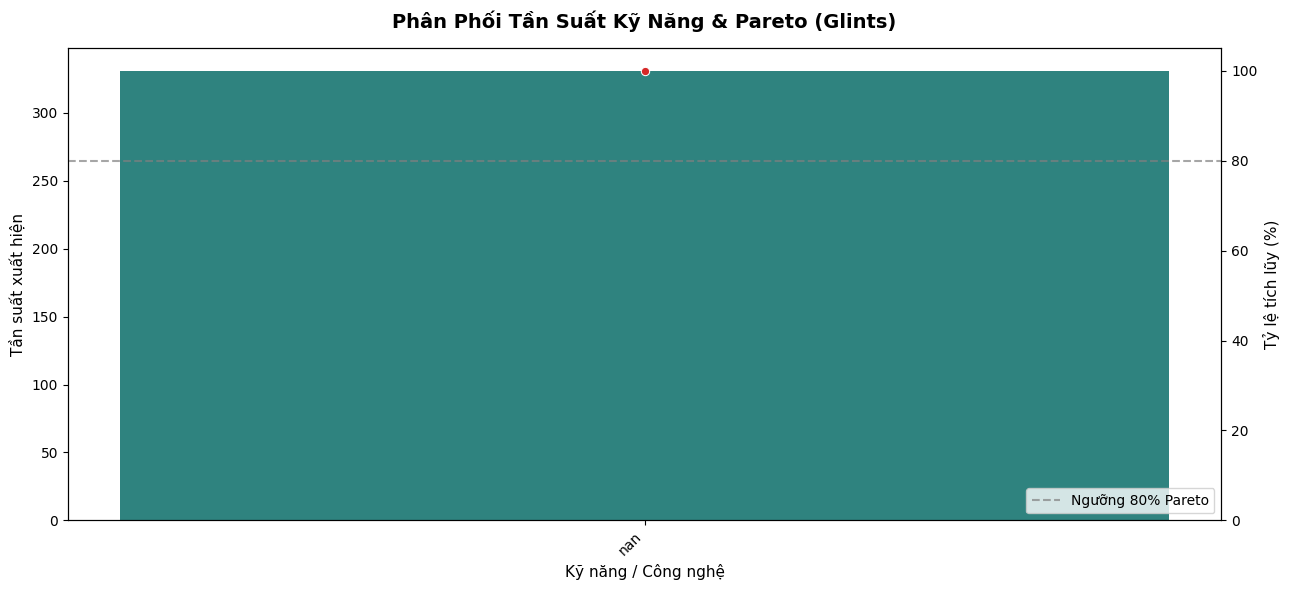

✅ Đã vẽ và lưu Biểu đồ Pareto Skills (Glints) tại: C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\03_skills_pareto_distribution.png


In [46]:
import os
import json
import ast
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

def flatten_glints_json(df):
    df_processed = df.copy()
    
    def extract_skills(row):
        raw = row.get('raw_payload')
        
        # 1. Xử lý trường hợp raw_payload bị Pandas đọc thành chuỗi (String)
        if isinstance(raw, str):
            try:
                raw = json.loads(raw)
            except Exception:
                try:
                    raw = ast.literal_eval(raw)
                except Exception:
                    pass

        if isinstance(raw, dict):
            # 2. Lấy trực tiếp từ raw_payload -> skills
            s_raw = raw.get('skills')
            if isinstance(s_raw, str) and s_raw.strip():
                # Phân tách bằng dấu phẩy (,) hoặc dấu gạch dọc (|)
                skills_list = [skill.strip() for skill in re.split(r'[,|]', s_raw) if skill.strip()]
                # Loại bỏ các từ khóa rác như "kỹ năng", "skills"
                return [s for s in skills_list if s.lower() not in ['kỹ năng', 'skills', '-']]

        # 3. Thử từ cột skills truyền thống nếu có sẵn
        if 'skills' in row:
            if isinstance(row['skills'], str) and row['skills'].strip():
                skills_list = [skill.strip() for skill in re.split(r'[,|]', row['skills']) if skill.strip()]
                return [s for s in skills_list if s.lower() not in ['kỹ năng', 'skills', '-']]
            elif isinstance(row['skills'], list):
                return row['skills']
        
        return []

    df_processed['parsed_skills'] = df_processed.apply(extract_skills, axis=1)
    return df_processed


def plot_skills_pareto_glints(df, save_path):
    # Thực hiện làm phẳng để lấy cột parsed_skills
    df_flat = flatten_glints_json(df)
    
    # Bung mảng kỹ năng và làm sạch
    all_skills = df_flat['parsed_skills'].dropna().explode().astype(str).str.strip()
    valid_skills = all_skills[(all_skills.str.len() > 0) & (all_skills.str.len() <= 30)]
    
    top20 = valid_skills.value_counts().head(20).reset_index()
    if top20.empty:
        print("❌ Không có dữ liệu kỹ năng hợp lệ để vẽ biểu đồ Pareto.")
        return
        
    top20.columns = ["Skill", "Frequency"]
    top20["Cum_Percent"] = (top20["Frequency"].cumsum() / top20["Frequency"].sum()) * 100
    
    # Thiết lập khung vẽ
    fig, ax1 = plt.subplots(figsize=(13, 6))
    ax2 = ax1.twinx()
    
    # Vẽ biểu đồ cột tần suất
    sns.barplot(data=top20, x="Skill", y="Frequency", ax=ax1, palette="viridis", hue="Skill", legend=False)
    
    # Fix cảnh báo ticklabels của matplotlib và xoay nhãn 45 độ
    ax1.set_xticks(range(len(top20["Skill"])))
    ax1.set_xticklabels(top20["Skill"], rotation=45, ha="right", fontsize=10)
    
    ax1.set_ylabel("Tần suất xuất hiện", fontsize=11)
    ax1.set_xlabel("Kỹ năng / Công nghệ", fontsize=11)
    
    # Vẽ đường tích lũy Pareto
    sns.lineplot(data=top20, x="Skill", y="Cum_Percent", ax=ax2, color="#d62828", marker="o", linewidth=2.5)
    ax2.axhline(80, color="gray", linestyle="--", alpha=0.7, label="Ngưỡng 80% Pareto")
    ax2.set_ylabel("Tỷ lệ tích lũy (%)", fontsize=11)
    ax2.set_ylim(0, 105)
    ax2.legend(loc="lower right")
    
    plt.title("Phân Phối Tần Suất Kỹ Năng & Pareto (Glints)", fontsize=14, fontweight='bold', pad=15)
    plt.tight_layout()
    
    # Lưu file vào đường dẫn yêu cầu
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    # HIỂN THỊ TRỰC TIẾP TRONG JUPYTER NOTEBOOK
    plt.show()
    plt.close()
    
    print(f"✅ Đã vẽ và lưu Biểu đồ Pareto Skills (Glints) tại: {save_path}")

# =================================================================
# THỰC THI TRONG NOTEBOOK
# =================================================================
path_chart_pareto = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\03_skills_pareto_distribution.png"
plot_skills_pareto_glints(df_glints_cleaned, path_chart_pareto)

HEATMAP


In [52]:
import os
import re
import json
import ast
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================
# 1. HÀM TIỀN XỬ LÝ & TRÍCH XUẤT ĐẶC TRƯNG SỐ HỌC (GLINTS)
# ==========================================
def extract_salary_min_max_glints(salary_val):
    """
    Bóc tách lương Min và Max từ chuỗi hoặc cấu trúc lương (baseSalary) của Glints
    """
    if pd.isna(salary_val):
        return np.nan, np.nan
        
    # Xử lý nếu lương là dictionary (cấu trúc JSON-LD)
    if isinstance(salary_val, dict):
        val_dict = salary_val.get('value', {})
        if isinstance(val_dict, dict):
            min_v = val_dict.get('minValue')
            max_v = val_dict.get('maxValue')
            def conv(v):
                if v is None: return np.nan
                try:
                    f = float(v)
                    return f / 1_000_000 if f >= 1000 else f
                except:
                    return np.nan
            return conv(min_v), conv(max_v)
        salary_str = str(salary_val)
    else:
        salary_str = str(salary_val)
        
    s = salary_str.lower().replace(',', '.')
    if 'thỏa thuận' in s or 'không công khai' in s or 'negotiable' in s:
        return np.nan, np.nan
        
    nums = [float(n) for n in re.findall(r'\d+\.?\d*', s)]
    if not nums:
        return np.nan, np.nan
        
    nums = [n / 1_000_000 if n >= 1000 else n for n in nums]
    if len(nums) >= 2:
        return min(nums), max(nums)
    elif len(nums) == 1:
        return nums[0], nums[0]
    return np.nan, np.nan

def extract_experience_years_glints(exp_val):
    """
    Bóc tách số năm kinh nghiệm từ chuỗi hoặc đối tượng experienceRequirements
    """
    if pd.isna(exp_val):
        return np.nan
    if isinstance(exp_val, dict):
        val = exp_val.get('monthsOfExperience') or exp_val.get('value')
        if val is not None:
            try:
                f = float(val)
                return f / 12.0 if f > 10 else f
            except:
                pass
        exp_str = str(exp_val)
    else:
        exp_str = str(exp_val)
        
    s = exp_str.lower()
    if 'chưa' in s or 'không' in s or 'fresh' in s:
        return 0.0
    nums = re.findall(r'\d+', s)
    return float(nums[0]) if nums else np.nan

def parse_glints_skills(row):
    """
    Trích xuất và làm sạch kỹ năng từ raw_payload (hỗ trợ cả dấu phẩy và dấu gạch dọc |)
    """
    raw = row.get('raw_payload')
    if isinstance(raw, str):
        try:
            raw = json.loads(raw)
        except:
            try:
                raw = ast.literal_eval(raw)
            except:
                raw = {}
                
    skills_raw = None
    if isinstance(raw, dict):
        skills_raw = raw.get('skills') or raw.get('job_posting_jsonld', {}).get('skills')
        
    if not skills_raw or str(skills_raw).strip() == '':
        skills_raw = row.get('skills')
        
    if isinstance(skills_raw, str) and skills_raw.strip():
        skills_list = [s.strip() for s in re.split(r'[,|]', skills_raw) if s.strip()]
        return [s for s in skills_list if s.lower() not in ['kỹ năng', 'skills', '-']]
    elif isinstance(skills_raw, list):
        return [str(s).strip() for s in skills_raw if str(s).strip()]
        
    return []


# ==========================================
# 2. HÀM VẼ MA TRẬN TƯƠNG QUAN HẠNG SPEARMAN (GLINTS)
# ==========================================
def plot_correlation_heatmap_glints(df, save_path):
    print("--- VẼ MA TRẬN TƯƠNG QUAN HẠNG SPEARMAN (GLINTS) ---")
    df_processed = df.copy()
    
    # 1. KHỞI TẠO DATAFRAME CHỨA BIẾN SỐ HỌC
    df_num = pd.DataFrame()
    
    # Trích xuất Lương
    def get_salary_source(row):
        raw = row.get('raw_payload')
        if isinstance(raw, str):
            try: raw = json.loads(raw)
            except: 
                try: raw = ast.literal_eval(raw)
                except: raw = {}
        if isinstance(raw, dict):
            sal = raw.get('salary') or raw.get('job_posting_jsonld', {}).get('baseSalary')
            if sal: return sal
        if 'salary' in row:
            return row['salary']
        return None

    print(" Đang trích xuất Lương Min/Max (Glints)...")
    salary_series = df_processed.apply(get_salary_source, axis=1)
    salary_tuples = salary_series.apply(extract_salary_min_max_glints)
    df_num['Salary_Min_M'] = salary_tuples.apply(lambda x: x[0])
    df_num['Salary_Max_M'] = salary_tuples.apply(lambda x: x[1])
        
    # Trích xuất Kinh nghiệm
    def get_exp_source(row):
        raw = row.get('raw_payload')
        if isinstance(raw, str):
            try: raw = json.loads(raw)
            except:
                try: raw = ast.literal_eval(raw)
                except: raw = {}
        if isinstance(raw, dict):
            exp = raw.get('requirements') or raw.get('job_posting_jsonld', {}).get('experienceRequirements')
            if exp: return exp
        for col in ['experience_summary', 'requirements']:
            if col in row: return row[col]
        return None

    print(" Đang trích xuất Số năm kinh nghiệm (Glints)...")
    exp_series = df_processed.apply(get_exp_source, axis=1)
    df_num['Years_of_Experience'] = exp_series.apply(extract_experience_years_glints)
        
    # Tạo biến đếm số lượng Kỹ năng
    print(" Đang đếm số lượng Tags kỹ năng (Glints)...")
    parsed_skills = df_processed.apply(parse_glints_skills, axis=1)
    df_num['Total_Skills_Count'] = parsed_skills.apply(len)
        
    # Tính toán độ dài văn bản JD (description + requirements)
    print(" Đang tính toán độ dài văn bản JD (Glints)...")
    def get_text_len(row, key):
        raw = row.get('raw_payload')
        if isinstance(raw, str):
            try: raw = json.loads(raw)
            except:
                try: raw = ast.literal_eval(raw)
                except: raw = {}
        if isinstance(raw, dict):
            val = raw.get(key) or raw.get('job_posting_jsonld', {}).get(key)
            if val: return len(str(val).split())
        if key in row and pd.notna(row[key]):
            if isinstance(row[key], list):
                return sum(len(str(item).split()) for item in row[key])
            return len(str(row[key]).split())
        return 0

    jd_desc = df_processed.apply(lambda r: get_text_len(r, 'description'), axis=1)
    jd_req = df_processed.apply(lambda r: get_text_len(r, 'requirements'), axis=1)
    df_num['JD_Word_Count'] = jd_desc + jd_req

    # 2. TÍNH TOÁN MA TRẬN TƯƠNG QUAN SPEARMAN
    corr_matrix = df_num.corr(method="spearman")
    
    if corr_matrix.isna().all().all():
        print("❌ Không đủ dữ liệu định lượng hợp lệ để vẽ Heatmap.")
        return None
        
    # 3. VẼ HEATMAP TRỰC QUAN
    plt.figure(figsize=(9, 7))
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    sns.heatmap(
        corr_matrix, 
        mask=mask, 
        annot=True,          
        fmt=".2f",           
        cmap="coolwarm",     
        vmin=-1, vmax=1,     
        linewidths=1.5, 
        cbar_kws={"shrink": 0.8},
        annot_kws={"size": 11, "weight": "bold"}
    )
    
    plt.title("Ma Trận Tương Quan Hạng Spearman\n(Các Thuộc Tính Định Lượng - Glints)", 
              fontsize=14, fontweight='bold', pad=20)
    
    plt.xticks(rotation=45, ha='right', fontsize=11)
    plt.yticks(rotation=0, fontsize=11)
    plt.tight_layout()
    
    # 4. LƯU FILE VÀ HIỂN THỊ
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
    
    print(f"✅ Hoàn tất! Đã lưu Heatmap tương quan Glints tại: {save_path}")
    return corr_matrix


# ==========================================
# THỰC THI PIPELINE VẼ BIỂU ĐỒ 5 (GLINTS)
# ==========================================
save_path_chart_5 = r"C:\Users\ADMIN\Documents\VSCODE\crawldata24h\VN-IT-Job-Mining\reports\figures\glints\05_spearman_correlation_matrix.png"
correlation_table_glints = plot_correlation_heatmap_glints(df_glints_cleaned, save_path_chart_5)
display(correlation_table_glints)

--- VẼ MA TRẬN TƯƠNG QUAN HẠNG SPEARMAN (GLINTS) ---
 Đang trích xuất Lương Min/Max (Glints)...
 Đang trích xuất Số năm kinh nghiệm (Glints)...
 Đang đếm số lượng Tags kỹ năng (Glints)...
 Đang tính toán độ dài văn bản JD (Glints)...
❌ Không đủ dữ liệu định lượng hợp lệ để vẽ Heatmap.


None